# 02 - LoRA on SAM 3 (team stack)

The LoRA adaptation arm on the native `sam3` package (`Sam3MedSeg`), across all three
datasets: BUSI, Kvasir, MoNuSAC.

Three sections: **(1)** build the model and verify the adapters landed where we think
they did, **(2)** the results all three datasets share, **(3)** the learning curves.

Scoring is not reimplemented here. Section 2 calls `scripts/eval_lora.py`, the same
entry point `scripts/slurm/eval_lora.sbatch` runs on the cluster, which in turn calls
the shared six-metric `scripts/eval_model.py` that every arm uses. The numbers below
are therefore the numbers in the report table, by construction rather than by
coincidence.

History (in git, not the working tree): the SAM 1 prototype lives in this notebook's
earlier versions (147K/93.7M, 0.157%); the HF-transformers SAM 3 verification was
notebook 03_Sam3_explore.ipynb, removed after the team standardized on the native
stack (see commit 6d38175). An earlier cross-dataset (BUSI-trained on Kvasir)
section was dropped once the report scope settled on within-dataset results.

**Kernel: select the `sam3-native` env** (the only one with the `sam3` package).

In [1]:
#autoreload, so edits to .py files show without restarting
%load_ext autoreload
%autoreload 2

## 1. Setup and unit tests

Imports, the qualitative helpers, and the unit tests for the LoRA pieces. No model is
built here and nothing touches a GPU -- this section costs seconds.

The two `Sam3MedSeg` builds moved down to section 2.1, where they are first needed, so
that the results table (section 2) and the learning curves (section 3) can be run on
their own. Those two read a CSV and three text logs respectively, so the no-hardware
path through this notebook is: this section, then 2, then 3.

In [2]:
import sys
sys.path.insert(0, "../src")
sys.path.insert(0, "../scripts")      # eval_model.py / eval_lora.py live here

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

from medseg.data.medseg_data import DataConfig, build_dataloaders
from medseg.models import Sam3MedSeg
from medseg.utils.device import get_device

device = get_device()
print("device:", device)     # sam3-native env; mps on this Mac


# --- qualitative helpers (metrics come from the shared evaluator, not from here) ---
@torch.no_grad()
def predict_prob(model, image):
    """One image -> lesion-probability map at the image's own size (model outputs 512)."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))
    prob = torch.sigmoid(logits)
    return F.interpolate(prob, size=image.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu()


def dice_of(prob, gt, thr=0.5):
    """Single-image Dice, for the panel titles only."""
    pred = (prob > thr).float()
    return (2 * (pred * gt).sum() / (pred.sum() + gt.sum() + 1e-6)).item()

device: mps


In [3]:
!pytest ../tests/test_lora.py -v

============================= test session starts ==============================
platform darwin -- Python 3.12.13, pytest-9.1.1, pluggy-1.6.0 -- /Users/nikhilclaude/anaconda3/envs/sam3-native/bin/python3.12
cachedir: .pytest_cache
rootdir: /Users/nikhilclaude/Documents/Projects/DeepLearning/group_project
plugins: anyio-4.14.2
collected 5 items                                                              

../tests/test_lora.py::test_output_shape PASSED                          [ 20%]
../tests/test_lora.py::test_zero_at_init PASSED                          [ 40%]
../tests/test_lora.py::test_param_count PASSED                           [ 60%]
../tests/test_lora.py::test_linear_with_lora PASSED                      [ 80%]
../tests/test_lora.py::test_lora_qkv_slices PASSED                       [100%]

============================== 5 passed in 1.00s ===============================


## 2. Results: all three datasets

One table for BUSI, Kvasir and MoNuSAC, from the shared evaluator rather than a
notebook-local metric. `scripts/eval_lora.py` reads each run's experiment config for the
two settings that must match training (`img_size` and `normalize`), loads that run's
checkpoint, and hands the model to `eval_model.evaluate`, which:

* scores at the model's own output resolution (512) and derives the NSD tolerance from
  it (2 px at 512), resizing ground truth to match rather than the other way round;
* drops MoNuSAC's Ambiguous class (5) as don't-care -- it has no training data and
  appears in 87 of 101 test images, so counting it would silently sink the score;
* macro-averages MoNuSAC over the nucleus classes present in each image.

`USE_CACHED = True` reads the CSV the cluster job already wrote. Set it to `False` to
re-run the evaluation locally through the identical code path -- correct but slow on a
Mac, since it rebuilds each backbone and runs ~430 forward passes at 1008 input.

In [4]:
from pathlib import Path

USE_CACHED = True                      # False -> recompute locally via eval_lora.score()
CSV = Path("../results/metrics/lora_eval.csv")
METRICS = ["precision", "recall", "f1", "iou", "dice", "nsd"]

if USE_CACHED:
    assert CSV.exists(), f"{CSV} not found -- run scripts/slurm/eval_lora.sbatch, or set USE_CACHED=False"
    scores = pd.read_csv(CSV)
else:
    from eval_lora import score, RUNS   # the exact entry point the cluster job uses
    for ds in RUNS:
        score(ds, device, csv_path=str(CSV))
    scores = pd.read_csv(CSV)

# one row per dataset/split; keep the last run of each if the CSV was appended to twice
scores = scores.drop_duplicates(subset=["dataset", "split"], keep="last")
print(f"eval raster: {sorted(scores.eval_size.unique())}   NSD tol: {sorted(scores.tol.unique())}")
scores

eval raster: [np.int64(512)]   NSD tol: [np.int64(2)]


,dataset,split,images,eval_size,tol,precision,recall,f1,iou,dice,nsd
0,busi,val,64,512,2,0.7822,0.8227,0.7819,0.7002,0.7819,0.3857
1,busi,test,131,512,2,0.7956,0.8279,0.7853,0.7072,0.7853,0.4009
2,kvasir,val,100,512,2,0.9489,0.9241,0.9269,0.8768,0.9269,0.6510
3,kvasir,test,200,512,2,0.9209,0.9409,0.9162,0.8655,0.9162,0.6586
4,monusac,val,21,512,2,0.8006,0.7377,0.7424,0.6169,0.7424,0.7247
5,monusac,test,101,512,2,0.8199,0.7477,0.7589,0.6379,0.7589,0.6340


In [5]:
# The report table: test split only.
test = scores[scores.split == "test"].set_index("dataset").loc[["busi", "kvasir", "monusac"]]

print(f"{'dataset':10s}{'images':>8s}" + "".join(f"{m:>11s}" for m in METRICS))
print("-" * (18 + 11 * len(METRICS)))
for ds, r in test.iterrows():
    print(f"{ds:10s}{int(r['images']):>8d}" + "".join(f"{r[m]:>11.4f}" for m in METRICS))

print("\nF1 == Dice for the binary sets by definition. MoNuSAC is macro-averaged over the\n"
      "four nucleus classes, each scored only on the images containing it, so its row is a\n"
      "different measurement from the other two -- three tasks, not a difficulty ranking.")

dataset     images  precision     recall         f1        iou       dice        nsd
------------------------------------------------------------------------------------
busi           131     0.7956     0.8279     0.7853     0.7072     0.7853     0.4009
kvasir         200     0.9209     0.9409     0.9162     0.8655     0.9162     0.6586
monusac        101     0.8199     0.7477     0.7589     0.6379     0.7589     0.6340

F1 == Dice for the binary sets by definition. MoNuSAC is macro-averaged over the
four nucleus classes, each scored only on the images containing it, so its row is a
different measurement from the other two -- three tasks, not a difficulty ranking.


### 2.1 Qualitative: BUSI and Kvasir

**This is where the model gets built, and where the notebook starts needing hardware.**
Two builds (trained + untrained baseline), ~1-2 min each, ~1.8 GB of weights apiece.
The forward passes are at 1008x1008 -- the head emits 512, but SAM 3's backbone input is
fixed at 1008 -- so budget roughly 30-60 s per image on CPU against under a second on an
H100. Drop `n_show` if you are on CPU.

Columns are image, ground truth, untrained prediction, trained prediction. The untrained
column is the same frozen backbone with a random head, so it isolates what the 1.07 M
trained parameters bought. Panel titles carry that image's Dice; the aggregate in
section 2 is the number to quote.

In [6]:
# The two binary-arm model builds, reused below (~1-2 min each on Mac).
model = Sam3MedSeg(finetune_mode="lora").to(device)      # gets each dataset's trained weights later
baseline = Sam3MedSeg(finetune_mode="lora").to(device)   # stays untrained = the before-picture

# injection targets: 32 fused-qkv layers in the vision backbone, each now wrapped by LoRA_qkv
blocks = model.backbone.backbone.vision_backbone.trunk.blocks
print(f"{len(blocks)} vision blocks | block[0].attn.qkv is now a {type(blocks[0].attn.qkv).__name__}")
print(blocks[0].attn.qkv)

# Freeze the 455M backbone, train only the adapters + FPN head. Expected:
#   1,066,113 / 455,105,921 (0.2343%) = 524,288 adapters (32 x 2 x 2*4*1024) + 541,825 head
# Any other number means the injection state is wrong (see docs/lora.md).
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"\n{trainable:,} / {total:,} trainable  ({100*trainable/total:.4f}%)")

/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model/sam3_video_inference.py:800: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)
/Users/nikhilclaude/Documents/Projects/DeepLearning/group_project/vendor/sam3-repo/sam3/model/sam3_video_inference.py:908: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)
/Users/nikhilclaude/anaconda3/envs/sam3-native/lib/python3.12/site-packages/timm/models/layers/__in

32 vision blocks | block[0].attn.qkv is now a LoRA_qkv
LoRA_qkv(
  (qkv): Linear(in_features=1024, out_features=3072, bias=True)
  (lora_q): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
  (lora_v): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
)

1,066,113 / 455,105,921 trainable  (0.2343%)


In [7]:
def show_binary(dataset, model, baseline, n_show=1, start=0):
    """Load `dataset`'s trained weights into `model` and show a few test examples.
    `dataset` is "busi" or "kvasir" -- it drives both the checkpoint and the matching
    test data, so the two cannot be mismatched. Cheap: 2 forward passes per row.
    `start` is the first test index shown; rows run start .. start+n_show-1."""
    ckpt = torch.load(f"../checkpoints/sam3_lora_{dataset}_full_512/best.pt", map_location=device)
    model.load_state_dict(ckpt["model"])
    test_ds = build_dataloaders(DataConfig.from_yaml(f"../configs/data/{dataset}.yaml"))["test"].dataset
    print(f"{dataset}: ckpt epoch {ckpt['epoch']} (val Dice {ckpt['dice']:.4f})  |  {len(test_ds)} test images")
    assert start + n_show <= len(test_ds), f"start={start} n_show={n_show} runs past {len(test_ds)} images"

    # squeeze=False keeps axes 2-D at n_show=1, so axes[row, col] still indexes
    fig, axes = plt.subplots(n_show, 4, figsize=(16, 4 * n_show), squeeze=False)
    for row in range(n_show):
        idx = start + row
        s = test_ds[idx]
        img, m = s["image"], s["mask"][0]
        prob_u = predict_prob(baseline, img)     # untrained (random head)
        prob_t = predict_prob(model, img)        # trained
        img_np = img.permute(1, 2, 0).numpy()
        axes[row, 0].imshow(img_np); axes[row, 0].set_title(f"{dataset} test[{idx}]")
        axes[row, 1].imshow(img_np); axes[row, 1].imshow(m, cmap="Reds", alpha=0.5)
        axes[row, 1].set_title("ground truth")
        axes[row, 2].imshow(prob_u, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title(f"untrained\ndice {dice_of(prob_u, m):.3f}")
        axes[row, 3].imshow(prob_t, cmap="viridis", vmin=0, vmax=1)
        axes[row, 3].set_title(f"trained\ndice {dice_of(prob_t, m):.3f}")
        for a in axes[row]:
            a.axis("off")
    plt.tight_layout(); plt.show()

busi: ckpt epoch 16 (val Dice 0.7819)  |  131 test images


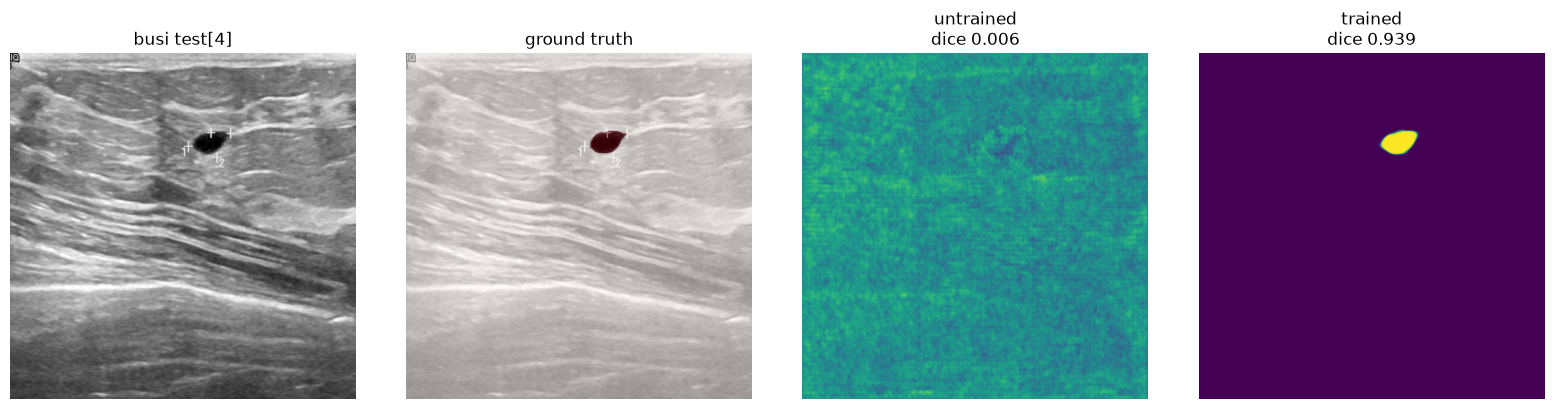

In [8]:
# BUSI - grayscale ultrasound, weak/diffuse boundaries
show_binary("busi", model, baseline, start=4)

kvasir: ckpt epoch 18 (val Dice 0.9269)  |  200 test images


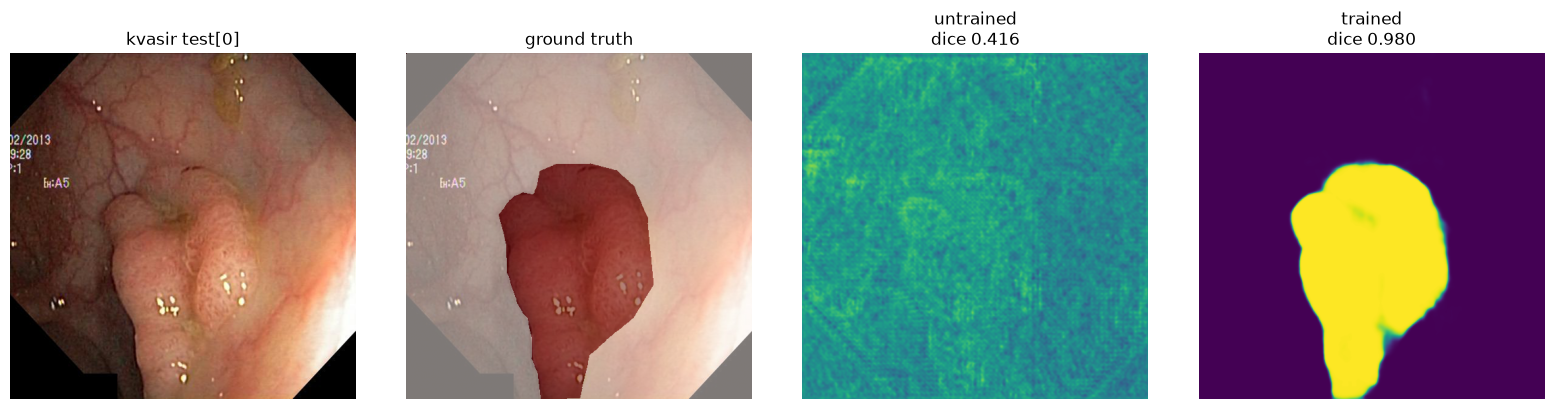

In [9]:
# Kvasir - RGB endoscopy, one large clear-boundaried polyp
show_binary("kvasir", model, baseline)

### 2.2 Qualitative: MoNuSAC (multi-class)

The only multi-class arm: four nucleus types to separate rather than one object to find,
which needs its own model build. The head emits `num_classes` channels, so the 5-class
weights are a different set from the binary ones and `model` above cannot be reused.

Note Macrophage appears in only 53 of 188 train images, so the macro average leans on
the rare classes.

In [10]:
from pathlib import Path
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from medseg.engine.metrics import resize_mask, seg_scores

MONUSAC_LABELS = ["background", "Epithelial", "Lymphocyte", "Macrophage", "Neutrophil", "Ambiguous"]
MONUSAC_NC = 5          # trainable classes 0-4; class 5 is GT-only and ignored
AMBIGUOUS = 5

# Wong/seaborn-colorblind steps for the four nucleus types: separated in hue AND
# lightness, so they survive colour-vision deficiency. Background near-white,
# Ambiguous mid-grey to read as "not a prediction target".
CLASS_COLORS = ["#f7f7f7", "#0173B2", "#DE8F05", "#029E73", "#CC78BC", "#999999"]
MC_CMAP = ListedColormap(CLASS_COLORS)
MC_NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), MC_CMAP.N)


@torch.no_grad()
def predict_labels(model, image):
    """One image -> (H,W) predicted class indices at the image's own resolution."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))                    # (1,5,512,512)
    lab = logits.argmax(1, keepdim=True).float()
    lab = F.interpolate(lab, size=image.shape[-2:], mode="nearest")  # nearest: never invent a class
    return lab[0, 0].cpu().long()


def mc_legend(ax):
    ax.legend(handles=[Patch(facecolor=CLASS_COLORS[c],
                             label=MONUSAC_LABELS[c] + (" (ignored)" if c == AMBIGUOUS else ""))
                       for c in range(1, 6)],
              loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)


def show_monusac(model, baseline, test_ds, indices=(5,)):
    """Qualitative panels only — 2 forward passes per row, so re-run freely.

    Index 5 is one of only two test images containing all four nucleus types (the
    other is 90, which is 24.5% Ambiguous pixels and renders mostly grey). Do NOT
    use test[0:5]: they are consecutive, and MoNuSAC is ordered by patient/organ, so
    they all show a single nucleus type and make a multi-class task look binary.
    Richer alternatives, 3 types each: 10, 46, 77.
    """
    # squeeze=False keeps axes 2-D for a single index, so axes[row, col] still indexes
    fig, axes = plt.subplots(len(indices), 4, figsize=(17, 4 * len(indices)), squeeze=False)
    for row, idx in enumerate(indices):
        s = test_ds[idx]
        img, gt = s["image"], s["mask"]                       # (3,H,W), (H,W) long
        img_np = img.permute(1, 2, 0).numpy()

        lab_u, lab_t = predict_labels(baseline, img), predict_labels(model, img)
        # per-image macro Dice, same metric as the aggregate
        d_u = seg_scores(F.one_hot(lab_u, MONUSAC_NC).permute(2, 0, 1)[None].float(),
                         gt[None], tol=2, ignore_index=AMBIGUOUS)[0]
        d_t = seg_scores(F.one_hot(lab_t, MONUSAC_NC).permute(2, 0, 1)[None].float(),
                         gt[None], tol=2, ignore_index=AMBIGUOUS)[0]

        n_cls = len(set(gt.unique().tolist()) - {0, AMBIGUOUS})
        panels = [(img_np, None, f"monusac test[{idx}]  ({n_cls} nucleus types)"),
                  (gt.numpy(), MC_CMAP, "ground truth"),
                  (lab_u.numpy(), MC_CMAP, f"untrained\nmacro dice {d_u:.3f}"),
                  (lab_t.numpy(), MC_CMAP, f"trained\nmacro dice {d_t:.3f}")]
        for col, (data, cm, title) in enumerate(panels):
            ax = axes[row, col]
            ax.imshow(data, cmap=cm, norm=MC_NORM if cm is not None else None)
            ax.set_title(title, fontsize=10)
            ax.axis("off")
        mc_legend(axes[row, 3])

    plt.tight_layout(); plt.show()

In [11]:
CKPT_MC = Path("../checkpoints/sam3_lora_monusac_full_512/best.pt")

model_mc    = Sam3MedSeg(finetune_mode="lora", num_classes=MONUSAC_NC).to(device)
baseline_mc = Sam3MedSeg(finetune_mode="lora", num_classes=MONUSAC_NC).to(device)   # untrained reference

tr = sum(p.numel() for p in model_mc.parameters() if p.requires_grad)
tot = sum(p.numel() for p in model_mc.parameters())
print(f"{tr:,} / {tot:,} trainable  ({100*tr/tot:.4f}%)   [binary arm: 1,066,113]")
# the +516 over the binary arm is the head's final 1x1 conv going 128->5 instead of 128->1

if CKPT_MC.exists():
    ck = torch.load(CKPT_MC, map_location=device)
    model_mc.load_state_dict(ck["model"])
    print(f"loaded {CKPT_MC}  (epoch {ck['epoch']}, val Dice {ck['dice']:.4f})")
else:
    ck = None
    print(f"NOT FOUND: {CKPT_MC}\n"
          f"  Run:  sbatch scripts/slurm/train_lora.sbatch configs/experiment/lora/baseline/sam3_lora_monusac_full.yaml\n"
          f"  The cell below will show the untrained model until the checkpoint exists.")

1,066,629 / 455,106,437 trainable  (0.2344%)   [binary arm: 1,066,113]
loaded ../checkpoints/sam3_lora_monusac_full_512/best.pt  (epoch 19, val Dice 0.7424)


monusac TEST: 101 images


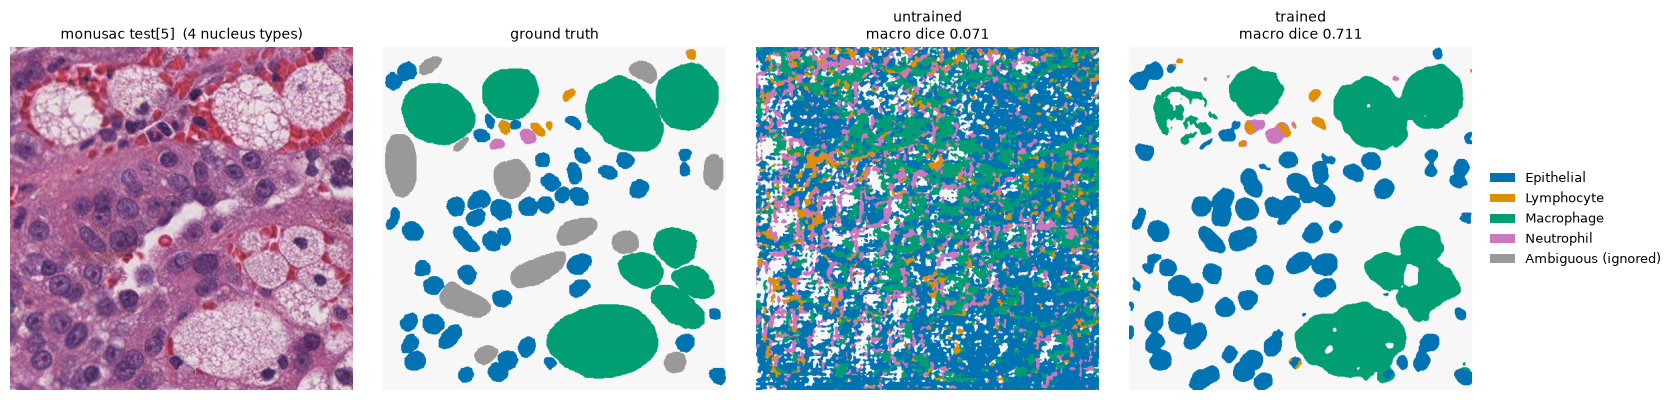

In [12]:
test_ds_mc = build_dataloaders(DataConfig.from_yaml("../configs/data/monusac.yaml"))["test"].dataset
print(f"monusac TEST: {len(test_ds_mc)} images")

# Default indices contain 3-4 nucleus types. test[0:5] are consecutive and MoNuSAC is
# ordered by patient/organ, so those five all show one type and make this look binary.
show_monusac(model_mc, baseline_mc, test_ds_mc)

## 3. Learning curves

The per-epoch history is not in the checkpoint -- `best.pt` stores only the single best
epoch. It is in the SLURM training logs, as the `epoch N: train_loss=... val_dice=...`
lines, which we parse here.

All three are the 512-head baselines of 2026-08-01, the same runs behind the table in
section 2. The dashed line marks the epoch that was actually saved.

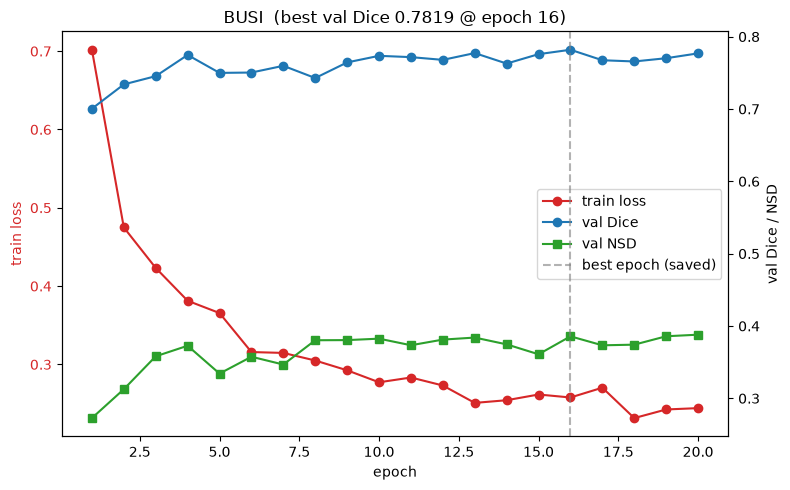

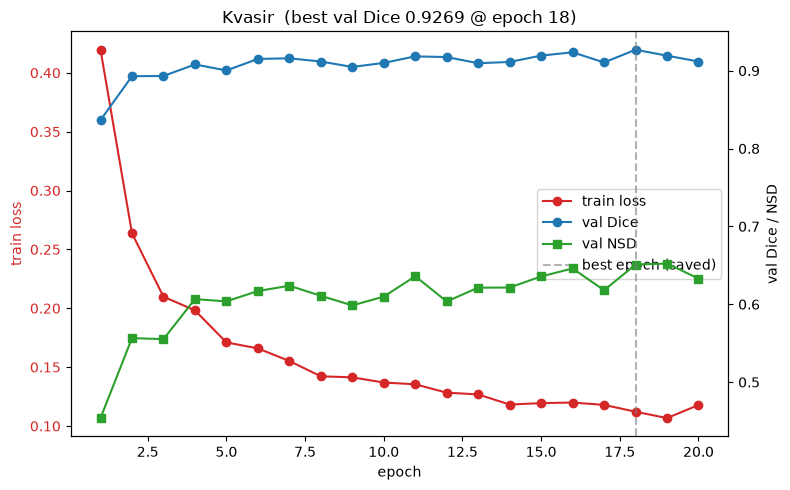

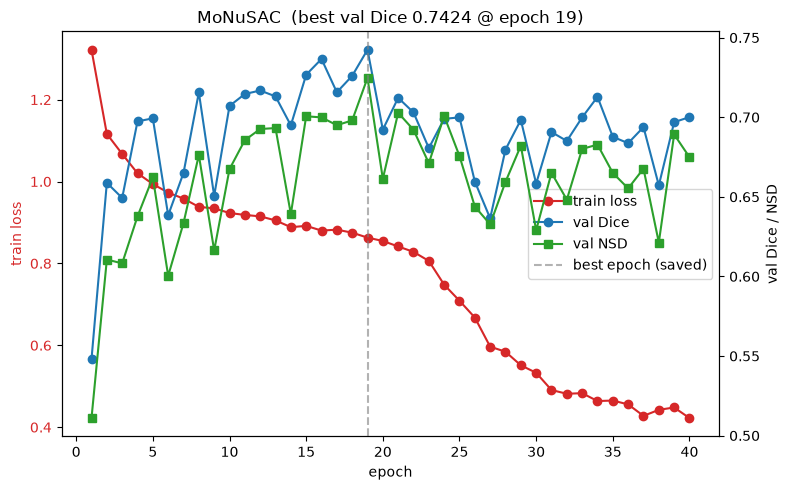

In [13]:
import re

def parse_log(path):
    """Extract per-epoch (train_loss, val_dice, val_nsd) from a SLURM training log."""
    pat = re.compile(r"epoch (\d+): train_loss=([\d.]+)\s+val_dice=([\d.]+)\s+val_nsd=([\d.]+)")
    rows = [m for m in (pat.search(l) for l in open(path)) if m]
    if not rows:
        raise ValueError(f"no epoch lines in {path} -- wrong job id, or the run died early")
    ep = [int(m.group(1)) for m in rows]
    return ep, [float(m.group(2)) for m in rows], [float(m.group(3)) for m in rows], [float(m.group(4)) for m in rows]


def plot_curve(path, title):
    ep, tl, vd, vn = parse_log(path)
    fig, ax1 = plt.subplots(figsize=(8, 5))
    l1, = ax1.plot(ep, tl, "C3-o", label="train loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss", color="C3")
    ax1.tick_params(axis="y", labelcolor="C3")
    ax2 = ax1.twinx()
    l2, = ax2.plot(ep, vd, "C0-o", label="val Dice")
    l3, = ax2.plot(ep, vn, "C2-s", label="val NSD")
    ax2.set_ylabel("val Dice / NSD")
    best = max(range(len(vd)), key=lambda i: vd[i])
    lbest = ax2.axvline(ep[best], ls="--", c="gray", alpha=0.6, label="best epoch (saved)")
    lines = [l1, l2, l3, lbest]
    ax1.legend(lines, [l.get_label() for l in lines], loc="center right")
    plt.title(f"{title}  (best val Dice {vd[best]:.4f} @ epoch {ep[best]})")
    plt.tight_layout(); plt.show()


# The 512-head baselines (2026-08-01). Job ids 5525699/5526204 are the earlier
# 256-data/1008-head era: their val_nsd is on a different scale (tol was hardcoded at
# 2px regardless of raster), so do not mix them into these plots.
plot_curve("../slurm_outs/lora/slurm_5554981.out", "BUSI")
plot_curve("../slurm_outs/lora/slurm_5554982.out", "Kvasir")
plot_curve("../slurm_outs/lora/slurm_5554983.out", "MoNuSAC")